# Персональные top-10 рекомендации книг

Войт Руслан, 117 группа, кафедра ММП.

В этом задании я сравню методы ItemKNN, iALS, EASE, FM с метапризнаками и iALS с собственным целевым сигналом на Goodreads Poetry.

Объектом рекомендации в данном случае будет произведение, а релевантность означает оценку 4 или 5.

## 1. Запуск и данные

Нужен Python 3.13 или 3.14. Из директории `hw1`: `pip install -r requirements.txt`, затем запустить все ячейки здесь. Недостающие данные скачиваются автоматически, папка `data/` исключена из Git.

По умолчанию модели обучаются с сохранёнными настройками. `RUN_SEARCH=True` повторяет подбор на validation и может существенно увеличить время выполнения.

Источник - [Goodreads Book Graph, UCSD](https://mengtingwan.github.io/data/goodreads.html), жанр poetry. Загружаются полки, рецензии и справочники изданий, произведений и авторов с [сервера авторов](https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/). Для файлов проверяется SHA-256.

| Поле | Значение                                      |
|---|-----------------------------------------------|
| user_id, book_id | пользователь и издание                        |
| work_id | произведение; разные издания объединяются     |
| rating | 1–5 - оценка, 0 - книга на полке без оценки   |
| date_added | дата добавления книги на полку                |
| date_updated, read_at | последняя правка и необязательная дата чтения |
| Метаданные | автор, издатель, год, страницы, формат, язык  |

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "DATA.md").exists() and (ROOT / "hw1/DATA.md").exists():
    ROOT = ROOT / "hw1"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

from utils import data as D
from utils.experiment import Experiment, search_spaces
from utils.metrics import bootstrap_ci, paired_bootstrap

SEED = 42
RUN_SEARCH = False
REBUILD_DATA = False
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
blas_threads = threadpool_limits(limits=1)
started = time.perf_counter()
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(90)

polars.config.Config

In [2]:
RAW = Path("data/raw/goodreads")
PROCESSED = Path("data/processed")
D.download(RAW)
data, preparation = D.prepare(RAW, PROCESSED, rebuild=REBUILD_DATA)
interactions, items = data["interactions"], data["items"]
display(pl.DataFrame(preparation["funnel"]))

step,interactions,users,items
str,i64,i64,i64
"""Исходные полки""",2734350,377799,36514
"""Корректные ID и дата""",2734350,377799,36514
"""Только оценки 1–5""",1229059,267821,36182
"""Издания → произведения, без дублей""",1222334,267821,25409
"""Окно 2007-01-01 … 2017-10-31""",1222200,267789,25408
"""Есть название и автор""",1222200,267789,25408
"""Без длинных однообразных историй""",1206340,267487,25337
"""Train k-core: user≥5, item≥10""",705500,51778,7576


## 2. Подготовка и EDA

Оставлены записи с корректными идентификаторами, датой и оценкой 1–5. Ноль я решил не считать отрицательной оценкой и в обучении не использую.

Издания объединены по work_id: оценка берётся из последней правки, а время из первого добавления. Это сохрангяет одно наблюдение на пару, но не восстанавливает историческое значение оценки.

Окно данных: 2007-01-01 … 2017-10-31. У произведения должны быть название и автор. Удалены пользователи с ≥20 оценками, из которых ≥95% одинаковы, кажется, они не вносят пользы. Затем только на train построено ядро: ≥5 оценок у пользователя и ≥10 у произведения. Validation и test отфильтрованы по этому ядру.

Фильтр однообразных историй вычисляется по всему периоду, и вместе с правилами датировки это ограничение временной постановки.

In [3]:
display(pl.DataFrame({"поле": list(preparation["missing"]),
                      "пропусков": list(preparation["missing"].values())}))
print("Дубликатов (user, work) до объединения:", preparation["work_duplicates"])
print("Исходное распределение rating (0 - без оценки):")
display(pl.DataFrame(preparation["raw_ratings"]))

activity = interactions.group_by("user_id").len()["len"]
popularity = interactions.group_by("item_id").len()["len"].sort(descending=True)
density = interactions.height / (activity.len() * popularity.len())
print(f"Итог: {interactions.height:,} оценок, {activity.len():,} пользователей, {popularity.len():,} произведений")
print(f"Разреженность: {1-density:.4%}; медиана оценок на пользователя: {activity.median():.0f}")
print(f"Топ-1% произведений: {popularity.head(max(1,int(popularity.len()*.01))).sum()/popularity.sum():.1%} оценок")

поле,пропусков
str,i64
"""user_id""",0
"""book_id""",0
"""rating""",0
"""date_added""",0
"""read_at""",2309891


Дубликатов (user, work) до объединения: 6725
Исходное распределение rating (0 — без оценки):


rating,len
i64,i64
0,1505291
1,20497
2,64084
3,237942
4,405565
5,500971


Итог: 705,500 оценок, 51,778 пользователей, 7,576 произведений
Разреженность: 99.8201%; медиана оценок на пользователя: 9
Топ-1% произведений: 35.8% оценок


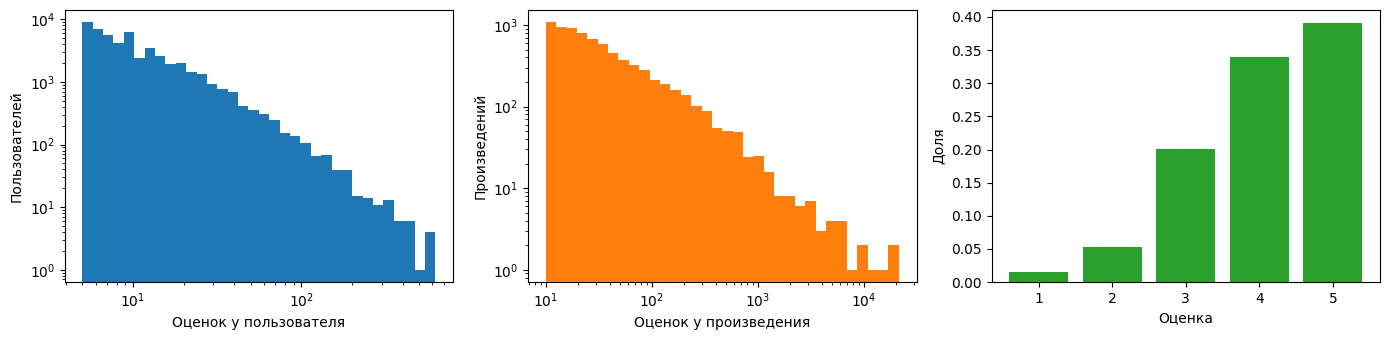

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(activity, bins=np.geomspace(5, activity.max()+1, 35))
axes[0].set(xscale="log", yscale="log", xlabel="Оценок у пользователя", ylabel="Пользователей")
axes[1].hist(popularity, bins=np.geomspace(10, popularity.max()+1, 35), color="C1")
axes[1].set(xscale="log", yscale="log", xlabel="Оценок у произведения", ylabel="Произведений")
rating_counts = interactions.group_by("rating").len().sort("rating")
axes[2].bar(rating_counts["rating"], rating_counts["len"]/interactions.height, color="C2")
axes[2].set(xlabel="Оценка", ylabel="Доля")
plt.tight_layout()
plt.show()

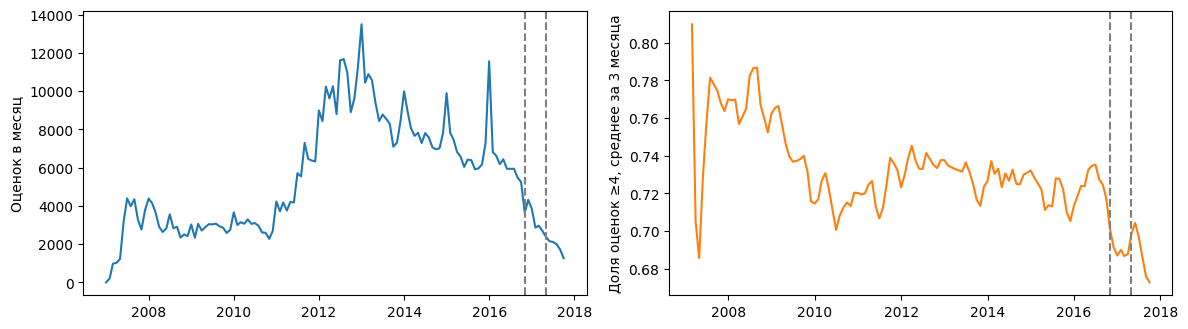

признак,заполненность,уникальных
str,f64,i64
"""author_id""",1.0,2939
"""publisher""",0.878,1942
"""publication_year""",0.986,396
"""num_pages""",0.924,997
"""format""",0.839,52
"""language_code""",0.505,47
"""description""",0.819,6164


In [5]:
monthly = interactions.group_by(pl.col("timestamp").dt.truncate("1mo").alias("month")).agg(
    pl.len().alias("n"), (pl.col("rating")>=4).mean().alias("share_positive")).sort("month")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(monthly["month"], monthly["n"])
axes[0].set(ylabel="Оценок в месяц")
axes[1].plot(monthly["month"], monthly["share_positive"].rolling_mean(3), color="C1")
axes[1].set(ylabel="Доля оценок ≥4, среднее за 3 месяца")
for ax in axes:
    for cutoff in [D.T1, D.T2]: ax.axvline(cutoff, ls="--", color="grey")
plt.tight_layout()
plt.show()

metadata_fields = ["author_id", "publisher", "publication_year", "num_pages", "format", "language_code", "description"]
display(pl.DataFrame([{"признак": c, "заполненность": round(items[c].is_not_null().mean(),3),
                       "уникальных": items[c].n_unique()} for c in metadata_fields]))

Активность и популярность имеют длинный хвост: большинство пользователей оценивают мало книг, а небольшая часть произведений собирает много взаимодействий. Поэтому сравниваю персональные модели с Popular. В метаданных пропуски не означают отсутствие признака: для категорий используется unknown, редкие издатели и авторы объединяются.

## 3. Протокол оценки

| Часть | Период | История для обучения и исключения |
|---|---|---|
| Train | до 2016-11-01 | - |
| Validation | 2016-11-01 … 2017-04-30 | train |
| Test | 2017-05-01 … 2017-10-31 | train + validation |

Кандидаты - все произведения train-каталога, кроме уже оценённых данным пользователем. Неоценённые книги с полки не исключаются. Оцениваются пользователи с хотя бы одной оценкой ≥4 в целевом периоде. Холодные пользователи и объекты исключены по train-ядру, поэтому холодный старт здесь не измеряется.

До подбора выбрана основная метрика **NDCG@10**: она учитывает позицию релевантной книги. **Recall@10** показывает долю найденных релевантных книг, **HitRate@10** - долю пользователей хотя бы с одним попаданием. Для каждого пользователя с множеством релевантных книг R:

$$\mathrm{NDCG@10}=\frac{\sum_{j=1}^{10}\mathbf1[l_j\in R]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R|)}1/\log_2(j+1)},\qquad
\mathrm{Recall@10}=\frac{\sum_{j=1}^{10}\mathbf1[l_j\in R]}{|R|}.$$

Усреднение - по пользователям с одинаковым весом. При равных скорах раньше идёт меньший индекс произведения; индексы строятся по идентификаторам, отсортированным как строки. Разбиение, кандидаты и релевантность одинаковы для всех моделей.

## 4. Модели

**ItemKNN.** X - бинарная матрица позитивных оценок. Косинусное сходство столбцов $s_{ij}=X_i^T X_j/(\|X_i\|\|X_j\|)$. В каждой строке S оставляю k соседей и обнуляю диагональ. Рекомендательный скор - строка $X_uS$.

**iALS.** Базовый сигнал $p_{ui}=\mathbf1[r_{ui}\ge4]$, $c_{ui}=1+\alpha p_{ui}$. Неизвестные пары имеют p=0, c=1. Минимизируется
$$\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$
Обновления чередуются: $x_u=(Y^TC_uY+\lambda I)^{-1}Y^TC_up_u$, аналогично для объектов. Общая часть $Y^TY$ считается один раз на полушаг, поправки - только по сохранённым парам.

**EASE.** Решается $\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2$ при diag(B)=0. Для $P=(X^TX+\lambda I)^{-1}$: $B_{ij}=-P_{ij}/P_{jj}$, $B_{ii}=0$. Скор - $X_uB$.

**FM.** Для разреженного вектора признаков z используется
$$\hat y(z)=w_0+w^Tz+\tfrac12\sum_d[(\sum_f v_{fd}z_f)^2-\sum_f v_{fd}^2z_f^2].$$
Обучение - BPR: $-\log\sigma(\hat y_{ui}-\hat y_{uj})$ с регуляризацией, где i - оценка ≥4, а j - случайная неоценённая книга. Члены, зависящие только от пользователя, сокращаются в разности и для ранжирования не вычисляются.

В FM входят ID, автор, издатель, бакеты года и объёма, формат, язык и популярность книги; профиль пользователя - активность, шкала оценок, давность взаимодействий, доли авторов и эпох. Динамические признаки считаются по истории до T1 для validation и до T2 для test. Средняя оценка книги и агрегаты сайта не используются. Дополнительно сравниваю FM только с ID при тех же dim/lr/reg.

**Кастомный iALS.** Смешиваю абсолютную релевантность и относительную оценку пользователя:
$$\mu_u=\frac{\sum_{i\in H_u}r_{ui}+5\mu_g}{|H_u|+5},\qquad
p_{ui}=(1-\eta)\mathbf1[r_{ui}\ge4]+\eta\,\sigma((r_{ui}-\mu_u)/\tau).$$
У выбранного варианта η=0.5, τ=0.5. Для неизвестных пар p=0. Confidence остаётся базовым: c=1+α для оценок ≥4, иначе 1. Высокие оценки сохраняют позитивный сигнал, а личная шкала даёт плавную поправку. Меняется именно p, а не только confidence. Решатель общий с базовым iALS.

In [6]:
experiment = Experiment(data, seed=SEED)
display(pl.DataFrame([{"часть": part, "оцениваемых пользователей": s["eval_users"].height,
                       "релевантных пар": s["relevant"].height, "каталог": experiment.n_items}
                      for part, s in experiment.stage.items()]))

часть,оцениваемых пользователей,релевантных пар,каталог
str,i64,i64,i64
"""val""",6551,13994,7576
"""test""",4274,8034,7576


## 5. Настройки и validation

| Модель | Проверенное пространство |
|---|---|
| ItemKNN | позитивы / все оценки; k ∈ {50,100,200,400} |
| EASE | позитивы / все оценки; λ ∈ {10,20,50,200,500,1000,3000} |
| iALS | 32/64/128 факторов; λ ∈ {0.001,0.01,0.1,1}; α ∈ {5,20,50}; 12 итераций |
| FM | dim ∈ {32,64}; lr ∈ {0.001,0.005}; reg ∈ {1e−5,1e−3}; до 15 эпох, early stopping по validation |
| Кастомный iALS | η ∈ {0.1,0.3,0.5}, α ∈ {10,20,30,40}; λ=0.1, затем уточнение λ и α у лучших точек |

Сохранённый validation-журнал находится в results/validation_search.csv; для исходного iALS в нём сохранены 10 лучших точек. Код повторного подбора доступен в scripts/tune.py и через RUN_SEARCH. Для обычного прогона использую уже выбранные настройки, включая число эпох FM.

**Ограничение отбора:** семейство кастомного сигнала уточнялось после просмотра test. Параметры выбранного семейства подбирались на validation, но сохранённый вариант оставлен после небольшого выигрыша на test. Его результат исследовательский; его нельзя считать новым независимым финальным тестом.

In [7]:
settings = json.loads(Path("results/config.json").read_text(encoding="utf-8"))
search_log = pl.read_csv("results/validation_search.csv")
if RUN_SEARCH:
    rows = []
    for name, space in search_spaces().items():
        log, settings[name] = experiment.search(name, space)
        rows.extend(log)
    id_config = {k: v for k, v in settings["FM"].items() if k != "epochs"}
    log, settings["FM (ID)"] = experiment.search("FM (ID)", [id_config])
    rows.extend(log)
    search_log = pl.DataFrame([{**r, "config": json.dumps(r["config"])} for r in rows])
    search_log.write_csv("results/search_repeated.csv")
display(pl.DataFrame([{"модель": name, "настройки": str(config)} for name, config in settings.items()]))
display(search_log.group_by("model").agg(pl.len().alias("записей в журнале"),
                                        pl.col("NDCG@10").max().round(5).alias("лучший validation NDCG@10")))

модель,настройки
str,str
"""Popular""","""{}"""
"""ItemKNN""","""{'signal': 'pos', 'k': 400}"""
"""EASE""","""{'signal': 'pos', 'reg': 50}"""
"""iALS""","""{'factors': 32, 'reg': 0.1, 'alpha': 20, 'iterations': 12}"""
"""iALS custom""","""{'strength': 0.5, 'temperature': 0.5, 'k': 5, 'factors': 32, 'reg': 0.1, 'alpha': 20, 'ite…"
"""FM""","""{'dim': 64, 'lr': 0.005, 'reg': 0.001, 'epochs': 9}"""
"""FM (ID)""","""{'dim': 64, 'lr': 0.005, 'reg': 0.001, 'epochs': 10}"""


model,записей в журнале,лучший validation NDCG@10
str,u32,f64
"""iALS custom""",17,0.08595
"""ItemKNN""",8,0.0755
"""FM""",8,0.0833
"""iALS""",10,0.0841
"""EASE""",14,0.0936


In [8]:
validation, val_summary = {}, {}
for name, config in settings.items():
    per_user, summary, _ = experiment.run(name, "val", config)
    validation[name], val_summary[name] = per_user, summary
    print(f"{name:12s} validation NDCG@10={summary['NDCG@10']:.6f}, Recall@10={summary['Recall@10']:.6f}", flush=True)

Popular      validation NDCG@10=0.041042, Recall@10=0.061541


ItemKNN      validation NDCG@10=0.075465, Recall@10=0.116686


EASE         validation NDCG@10=0.093634, Recall@10=0.150365


iALS         validation NDCG@10=0.084059, Recall@10=0.135749


iALS custom  validation NDCG@10=0.085947, Recall@10=0.136840


FM           validation NDCG@10=0.083294, Recall@10=0.125272


FM (ID)      validation NDCG@10=0.078039, Recall@10=0.121433


## 6. Обучение на train+validation и test

Все модели переобучаются на train+validation с теми же настройками. У FM признаки пересчитываются на T2, у кастомного iALS средние пользователя и общий рейтинг также берутся только до T2. Релевантность test остаётся оценкой ≥4. Выдачи сохраняются в data/outputs/.

In [9]:
test, test_summary = {}, {}
output_dir = Path("data/outputs")
output_dir.mkdir(parents=True, exist_ok=True)
for name, config in settings.items():
    per_user, summary, recs = experiment.run(name, "test", config)
    test[name], test_summary[name] = per_user, summary
    slug = name.replace(" ", "_").replace("(", "").replace(")", "")
    recs.select("user_id", "rank", "item_id").write_parquet(output_dir/f"{slug}_recs.parquet")
    per_user.write_parquet(output_dir/f"{slug}_metrics.parquet")
    assert recs.height == per_user.height * 10
    assert recs.select("user_id", "item_id").n_unique() == recs.height
    print(f"{name:12s} test NDCG@10={summary['NDCG@10']:.6f}, Recall@10={summary['Recall@10']:.6f}", flush=True)

Popular      test NDCG@10=0.042307, Recall@10=0.064978


ItemKNN      test NDCG@10=0.080266, Recall@10=0.127870


EASE         test NDCG@10=0.099922, Recall@10=0.159217


iALS         test NDCG@10=0.089065, Recall@10=0.144573


iALS custom  test NDCG@10=0.089605, Recall@10=0.144947


FM           test NDCG@10=0.085878, Recall@10=0.134676


FM (ID)      test NDCG@10=0.077770, Recall@10=0.126459


## 7. Итоговое сравнение

В таблице - средние по пользователям; для test NDCG@10 указан 95% перцентильный bootstrap-интервал, 1000 повторов, seed=42. Сравнение кастомного и базового iALS, а также FM с признаками и без них дополнено парным bootstrap по одним и тем же пользователям.

In [10]:
rows = []
ndcg_intervals = {}
for name in settings:
    mean, low, high = bootstrap_ci(test[name]["ndcg10"].to_numpy(), seed=SEED)
    ndcg_intervals[name] = (mean, low, high)
    rows.append({"model": name, "parameters": json.dumps(settings[name]),
                 "val_ndcg10": val_summary[name]["NDCG@10"], "val_recall10": val_summary[name]["Recall@10"],
                 "test_ndcg10": mean, "test_recall10": test_summary[name]["Recall@10"],
                 "test_hit10": test_summary[name]["HitRate@10"], "ndcg_low": low, "ndcg_high": high})
results = pl.DataFrame(rows).sort("test_ndcg10", descending=True)
results.write_csv("results/final.csv")
with pl.Config(tbl_cols=-1, tbl_width_chars=220, fmt_str_lengths=130):
    display(results.with_columns(pl.selectors.numeric().round(5)))

model,parameters,val_ndcg10,val_recall10,test_ndcg10,test_recall10,test_hit10,ndcg_low,ndcg_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""EASE""","""{""signal"": ""pos"", ""reg"": 50}""",0.09363,0.15037,0.09992,0.15922,0.22274,0.0934,0.10646
"""iALS custom""","""{""strength"": 0.5, ""temperature"": 0.5, ""k"": 5, ""factors"": 32, ""reg"": 0.1, ""alpha"": 20, ""iterations"": 12}""",0.08595,0.13684,0.0896,0.14495,0.2059,0.08341,0.09598
"""iALS""","""{""factors"": 32, ""reg"": 0.1, ""alpha"": 20, ""iterations"": 12}""",0.08406,0.13575,0.08907,0.14457,0.20519,0.08286,0.09578
"""FM""","""{""dim"": 64, ""lr"": 0.005, ""reg"": 0.001, ""epochs"": 9}""",0.08329,0.12527,0.08588,0.13468,0.19467,0.07936,0.09227
"""ItemKNN""","""{""signal"": ""pos"", ""k"": 400}""",0.07547,0.11669,0.08027,0.12787,0.18063,0.07465,0.08648
"""FM (ID)""","""{""dim"": 64, ""lr"": 0.005, ""reg"": 0.001, ""epochs"": 10}""",0.07804,0.12143,0.07777,0.12646,0.18039,0.07178,0.08426
"""Popular""","""{}""",0.04104,0.06154,0.04231,0.06498,0.08891,0.03775,0.04701


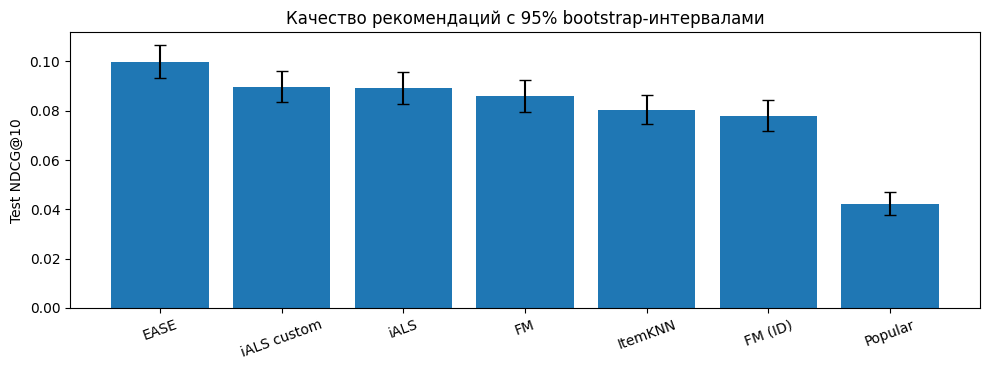

In [11]:
names = results["model"].to_list()
means = np.array([ndcg_intervals[n][0] for n in names])
errors = np.array([[m-lo, hi-m] for m,lo,hi in [ndcg_intervals[n] for n in names]]).T
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(names, means, yerr=errors, capsize=4)
ax.set(ylabel="Test NDCG@10", title="Качество рекомендаций с 95% bootstrap-интервалами")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [12]:
paired_rows = []
for a, b in [("iALS custom", "iALS"), ("FM", "FM (ID)"), ("EASE", "iALS")]:
    assert test[a]["user_idx"].equals(test[b]["user_idx"])
    for metric in ["ndcg10", "recall10"]:
        mean, low, high = paired_bootstrap(test[a][metric].to_numpy(), test[b][metric].to_numpy(), seed=SEED)
        paired_rows.append({"comparison": f"{a} − {b}", "metric": metric,
                            "difference": mean, "low": low, "high": high})
paired = pl.DataFrame(paired_rows)
paired.write_csv("results/paired.csv")
display(paired.with_columns(pl.selectors.numeric().round(6)))

comparison,metric,difference,low,high
str,str,f64,f64,f64
"""iALS custom − iALS""","""ndcg10""",0.00054,-0.001408,0.002418
"""iALS custom − iALS""","""recall10""",0.000374,-0.003704,0.004403
"""FM − FM (ID)""","""ndcg10""",0.008108,0.002794,0.013445
"""FM − FM (ID)""","""recall10""",0.008217,-0.000268,0.017245
"""EASE − iALS""","""ndcg10""",0.010857,0.005895,0.015482
"""EASE − iALS""","""recall10""",0.014643,0.006215,0.02223


## 8. Выводы

In [13]:
best = max(test_summary, key=lambda name: test_summary[name]["NDCG@10"])
base = test_summary["iALS"]["NDCG@10"]
custom = test_summary["iALS custom"]["NDCG@10"]
meta_delta = test_summary["FM"]["NDCG@10"] - test_summary["FM (ID)"]["NDCG@10"]
custom_interval = paired.filter((pl.col("comparison")=="iALS custom − iALS") & (pl.col("metric")=="ndcg10")).row(0, named=True)
custom_significant = custom_interval["low"] > 0 or custom_interval["high"] < 0
text = f"""Лучшая модель - **{best}**: test NDCG@10 = **{test_summary[best]['NDCG@10']:.5f}**, Recall@10 = {test_summary[best]['Recall@10']:.5f}.

Кастомный iALS получил NDCG@10 = **{custom:.6f}** против **{base:.6f}** у базового: разность {custom-base:+.6f}, относительное изменение {(custom/base-1)*100:+.2f}%. Парный интервал [{custom_interval['low']:.6f}, {custom_interval['high']:.6f}] {'не содержит' if custom_significant else 'содержит'} ноль. Малый численный выигрыш не доказывает устойчивого преимущества, особенно с учётом повторного просмотра test.

Добавление метапризнаков к FM изменило NDCG@10 на **{meta_delta:+.5f}** относительно ID-варианта при тех же dim/lr/reg. Парные интервалы выше показывают, насколько это различие убедительно. Это абляция признаков, а не независимый оптимальный подбор FM только с ID.

Мягкий кастомный сигнал сохраняет абсолютный критерий релевантности и добавляет персональную поправку. Его эффект значительно скромнее различий между семействами моделей; в этой задаче выбор самого метода оказался важнее такой поправки."""
display(Markdown(text))

Лучшая модель — **EASE**: test NDCG@10 = **0.09992**, Recall@10 = 0.15922.

Кастомный iALS получил NDCG@10 = **0.089605** против **0.089065** у базового: разность +0.000540, относительное изменение +0.61%. Парный интервал [-0.001408, 0.002418] содержит ноль. Малый численный выигрыш не доказывает устойчивого преимущества, особенно с учётом повторного просмотра test.

Добавление метапризнаков к FM изменило NDCG@10 на **+0.00811** относительно ID-варианта при тех же dim/lr/reg. Парные интервалы выше показывают, насколько это различие убедительно. Это абляция признаков, а не независимый оптимальный подбор FM только с ID.

Мягкий кастомный сигнал сохраняет абсолютный критерий релевантности и добавляет персональную поправку. Его эффект значительно скромнее различий между семействами моделей; в этой задаче выбор самого метода оказался важнее такой поправки.

Ограничения эксперимента:

- Один временной сплит, один seed и только тёплые пользователи/объекты. Точность не измеряет разнообразие и новизну.
- date_added - время добавления на полку, а не гарантированная дата выставления оценки. Склейка изданий соединяет позднее значение оценки с ранней датой. Фильтр однообразных историй использует весь период.
- Метаданные взяты из снимка конца 2017 года. Статические характеристики считаются известными, но выбор представительного издания зависит от этого снимка. Динамические признаки считаются до отсечки; обучающие профили включают собственные обучающие пары.
- Семейство кастомного таргета уточнялось с просмотром test. Его небольшой выигрыш - исследовательское наблюдение, а не подтверждение улучшения на независимом тесте.

In [14]:
import platform
import scipy
import matplotlib
versions = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "polars": pl.__version__, "torch": torch.__version__, "matplotlib": matplotlib.__version__}
runtime = {"versions": versions, "seed": SEED, "blas_threads": 1,
           "elapsed_seconds": time.perf_counter()-started,
           "validation_seconds": {n: s["seconds"] for n,s in val_summary.items()},
           "test_seconds": {n: s["seconds"] for n,s in test_summary.items()}}
Path("results/runtime.json").write_text(json.dumps(runtime, ensure_ascii=False, indent=2), encoding="utf-8")
print(versions)
print(f"Время этого прогона: {runtime['elapsed_seconds']/60:.2f} мин.")

{'python': '3.14.0', 'numpy': '2.4.2', 'scipy': '1.17.1', 'polars': '2.1.0', 'torch': '2.11.0+cu128', 'matplotlib': '3.10.8'}
Время этого прогона: 9.69 мин.
